# Assignment 16: Gaussian Naive Bayes – Classifying High and Low Spending Customers

In this assignment I use Gaussian Naive Bayes to classify customers based on whether their total spending is above or below a threshold (the median).

The assignment originally uses the Insurance Charges dataset. I used the Customer Personality Analysis dataset from Kaggle instead, because it is a real marketing dataset that connects to my background in digital marketing, and it fits every step of the assignment: it has continuous features, categorical features to encode, a money amount to turn into a binary target (total customer spending instead of medical charges), and real missing values to handle. I already used the insurance dataset in Assignment 11.

Dataset:
- Name: Customer Personality Analysis
- Source: Kaggle (uploaded by Akash Patel, imakash3011) – https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis
- Context: a company's customer database, used to understand customers and target marketing campaigns
- Target: high_spender, which I will create from the customers' total spending over the last 2 years (1 = above the median, 0 = at or below the median)

Gaussian Naive Bayes is a probabilistic classifier. It uses Bayes' Theorem and assumes that each continuous feature follows a normal (bell-shaped) distribution within each class, and that the features are independent of each other given the class.

Steps I will follow:
1. Import libraries and load the data
2. Inspect the structure and remove duplicates
3. Split the data into training (70%) and testing (30%) sets
4. Check and handle missing values
5. Generate summary statistics and visualize the continuous features
6. Encode the categorical variables and create the target variable
7. Train and evaluate a Gaussian Naive Bayes model (accuracy, precision, recall, F1-score)
8. Confusion matrix, ROC curve and AUC
9. Try feature scaling and compare the results
10. Write a report

## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, RocCurveDisplay)

pd.set_option("display.max_columns", None)
random_seed = 42

In [2]:
cust = pd.read_csv("marketing_campaign.csv", sep="\t")

In [3]:
print("Shape:", cust.shape)

Shape: (2240, 29)


In [4]:
display(cust.head())

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [5]:
cust.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

## Dataset Description

The dataset has one row per customer. The columns come in four groups, as described on the Kaggle page. Planned roles are in brackets.

### 1. Customer information
- ID: unique customer ID (not used as a feature, because it is only an identifier)
- Year_Birth: customer's birth year (used to create an Age feature)
- Education: education level, such as Graduation, PhD, Master, Basic and 2n Cycle (categorical, will be encoded)
- Marital_Status: marital status, such as Married, Together, Single, Divorced and Widow (categorical, will be encoded)
- Income: customer's yearly household income (continuous feature)
- Kidhome: number of small children in the household (count feature)
- Teenhome: number of teenagers in the household (count feature)
- Dt_Customer: date the customer joined the company (used to create a Customer_Days feature, meaning how long they have been a customer)
- Recency: number of days since the customer's last purchase (continuous feature)
- Complain: 1 if the customer complained in the last 2 years, otherwise 0

### 2. Products: amount spent in the last 2 years
- MntWines: amount spent on wine
- MntFruits: amount spent on fruits
- MntMeatProducts: amount spent on meat
- MntFishProducts: amount spent on fish
- MntSweetProducts: amount spent on sweets
- MntGoldProds: amount spent on gold products

These six columns will be added together to create Total_Spend, which is used to build the target. They will then be removed from the features, because the target is made from them. Keeping them would give the model the answer (data leakage).

### 3. Promotions
- NumDealsPurchases: number of purchases made with a discount
- AcceptedCmp1 to AcceptedCmp5: 1 if the customer accepted the offer in marketing campaign 1, 2, 3, 4 or 5, otherwise 0
- Response: 1 if the customer accepted the offer in the last campaign, otherwise 0

### 4. Place (sales channel)
- NumWebPurchases: number of purchases made through the company's website
- NumCatalogPurchases: number of purchases made using a catalogue
- NumStorePurchases: number of purchases made directly in stores
- NumWebVisitsMonth: number of visits to the company's website in the last month (continuous feature)

### 5. Other columns
- Z_CostContact and Z_Revenue: these are not described on the Kaggle page. I will check them during exploration.

### Target variable
- Total_Spend = MntWines + MntFruits + MntMeatProducts + MntFishProducts + MntSweetProducts + MntGoldProds
- high_spender = 1 if Total_Spend is above the median of the training data (high spender), otherwise 0 (low spender)

This is the same idea as the assignment's high_charge target (medical charges above or below the median).

### Planned continuous features for Gaussian Naive Bayes
Income, Age, Recency, NumWebVisitsMonth and Customer_Days. I will confirm the final features after exploring the data.

In [6]:
print("\nMissing values per column:\n", cust.isnull().sum()[cust.isnull().sum() > 0])



Missing values per column:
 Income    24
dtype: int64


In [7]:
print("Duplicate rows:", cust.duplicated().sum())

Duplicate rows: 0


In [8]:
print("Duplicate rows ignoring ID:", cust.drop(columns="ID").duplicated().sum())

Duplicate rows ignoring ID: 182


### Interpretation: Dataset Structure

The dataset has 2,240 rows (customers) and 29 columns. 26 columns are numeric and 3 are stored as text: Education, Marital_Status and Dt_Customer. Dt_Customer is a date in day-month-year format, so I will convert it to a date before using it.

Missing values:
Only Income has missing values (24 customers). I will handle them after splitting the data, so the test data does not influence how I fill them.

Duplicates:
There are no exact duplicate rows, but that is only because every row has a unique ID. When I ignore the ID, 182 rows are exact copies of other rows in all 28 remaining columns. It is practically impossible for two different customers to have the same birth year, income, join date, spending on all six product types and the same campaign responses, so these are the same customers recorded twice under different IDs. I will remove them before splitting. Otherwise a customer could appear in both the training and test sets, and the model would be tested on customers it has already seen.

Other observations:
In the first rows, Z_CostContact is always 3 and Z_Revenue is always 11. They may be constant columns with no useful information, so I will check them during exploration.

## Step 3: Remove Duplicates and Split the Data into Training (70%) and Testing (30%) Sets

In [9]:
# 1. Remove duplicate customers (identical in every column except ID)
cust = cust.drop_duplicates(subset=cust.columns.drop("ID")).reset_index(drop=True)
print("Shape after removing duplicates:", cust.shape)

Shape after removing duplicates: (2058, 29)


In [10]:
# 2. Split the whole table 70/30 (the target is created after the split, from the training median)
train_df, test_df = train_test_split(cust, test_size=0.3, random_state=random_seed)

print("Training set:", train_df.shape)
print("Testing set: ", test_df.shape)
print("Shared customer IDs between train and test:", len(set(train_df["ID"]) & set(test_df["ID"])))

Training set: (1440, 29)
Testing set:  (618, 29)
Shared customer IDs between train and test: 0


### Interpretation: Removing Duplicates and Splitting the Data

After removing the 182 duplicate customers, the dataset has 2,058 unique customers.

I split the data into a training set of 1,440 customers (70%) and a testing set of 618 customers (30%), as the assignment asks. No customer ID appears in both sets, so the model will be tested only on customers it has never seen.

I did not stratify the split, because the target variable does not exist yet. I will create it after the split, using the median spending of the training set only, so that the test data does not influence the threshold. A median split creates two roughly equal classes, and I will check the class balance after creating the target.

## Step 4: Check for Missing Values and Handle Them

In [11]:
train_df = train_df.copy()
test_df = test_df.copy()

print("Missing values - train:\n", train_df.isnull().sum()[train_df.isnull().sum() > 0])
print("\nMissing values - test:\n", test_df.isnull().sum()[test_df.isnull().sum() > 0])

Missing values - train:
 Income    18
dtype: int64

Missing values - test:
 Income    6
dtype: int64


In [12]:
# Income summary on training data, to choose mean or median
print("\nIncome (train) - mean:", round(train_df["Income"].mean(), 2),
      "| median:", train_df["Income"].median(),
      "| max:", train_df["Income"].max(),
      "| skewness:", round(train_df["Income"].skew(), 2))


Income (train) - mean: 52825.39 | median: 51523.5 | max: 666666.0 | skewness: 8.35


In [13]:
# Fill missing Income with the TRAINING median (used for both sets)
income_median = train_df["Income"].median()
train_df["Income"] = train_df["Income"].fillna(income_median)
test_df["Income"] = test_df["Income"].fillna(income_median)

print("\nMissing values after filling - train:", train_df.isnull().sum().sum(),
      "| test:", test_df.isnull().sum().sum())



Missing values after filling - train: 0 | test: 0


### Interpretation: Missing Values

Income was the only column with missing values: 18 in the training set and 6 in the testing set.

To choose how to fill them, I checked Income in the training data. The mean is 52,825 and the median is 51,523.5, but the maximum is 666,666 and the skewness is 8.35, which is extremely high. The value 666,666 is about 13 times the median and looks like a placeholder or data-entry error. It pulls the mean and the skewness up. The median is not affected by such extreme values, so I filled the missing incomes with the training median (51,523.5). I applied the same value to the test set, so the test data did not influence the fill value.

I chose to fill instead of drop because only about 1% of customers were missing Income, and dropping them would also remove their other 27 columns. After filling, there are no missing values in either set.

## Step 5: Create Continuous Features and Generate Summary Statistics

In [14]:
# Convert the join date from text to a real date
for df in [train_df, test_df]:
    df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")


In [15]:
# Reference date = the latest join date in the TRAINING data (around when the data was collected)
ref_date = train_df["Dt_Customer"].max()
print("Reference date:", ref_date.date())

for df in [train_df, test_df]:
    df["Age"] = ref_date.year - df["Year_Birth"]
    df["Customer_Days"] = (ref_date - df["Dt_Customer"]).dt.days
    df["Total_Spend"] = df[["MntWines", "MntFruits", "MntMeatProducts",
                            "MntFishProducts", "MntSweetProducts", "MntGoldProds"]].sum(axis=1)

cont_cols = ["Age", "Income", "Recency", "NumWebVisitsMonth", "Customer_Days", "Total_Spend"]
print("\nSummary statistics (training data):")
display(train_df[cont_cols].describe().T.round(2))
print("Skewness:\n", train_df[cont_cols].skew().round(2))

Reference date: 2014-06-29

Summary statistics (training data):


,count,mean,std,min,25%,50%,75%,max
Age,1440.0,45.12,12.07,18.0,36.00,44.0,55.00,115.0
Income,1440.0,52809.11,26984.98,2447.0,35789.50,51523.5,68454.50,666666.0
Recency,1440.0,48.85,29.21,0.0,24.00,49.0,74.00,99.0
NumWebVisitsMonth,1440.0,5.30,2.44,0.0,3.00,6.0,7.00,20.0
Customer_Days,1440.0,351.98,201.36,0.0,178.75,350.0,524.25,697.0
Total_Spend,1440.0,617.17,613.69,5.0,68.00,401.0,1064.25,2525.0


Skewness:
 Age                  0.34
Income               8.40
Recency              0.01
NumWebVisitsMonth    0.23
Customer_Days       -0.01
Total_Spend          0.86
dtype: float64


In [16]:
# Check the two undocumented columns
print("\nUnique values - Z_CostContact:", train_df["Z_CostContact"].unique(),
      "| Z_Revenue:", train_df["Z_Revenue"].unique())



Unique values - Z_CostContact: [3] | Z_Revenue: [11]


### Interpretation: Continuous Features and Summary Statistics

I created three new features: Age (the reference year minus the birth year), Customer_Days (how many days the customer had been with the company) and Total_Spend (the total amount spent on all six product types). I used the latest join date in the training data, 29 June 2014, as the reference date, because it is close to when the data was collected.

Summary of the training data:
- Age: from 18 to 115, with a mean of 45 and a median of 44. An age of 115 is not realistic and is probably an error in the birth year.
- Income: from 2,447 to 666,666, with a median of 51,523.5. 75% of customers earn less than 68,455, so 666,666 is an extreme outlier.
- Recency: from 0 to 99 days since the last purchase, evenly spread (mean 48.9, median 49).
- NumWebVisitsMonth: from 0 to 20 visits per month, with a median of 6.
- Customer_Days: from 0 to 697 days, so customers joined over about two years, up to June 2014.
- Total_Spend: from 5 to 2,525 over two years. The mean (617) is much higher than the median (401), because a smaller group of customers spends a lot. The training median of 401 will be the threshold for my target variable.

Skewness:
Age, Recency, NumWebVisitsMonth and Customer_Days are close to symmetric (skewness between -0.01 and 0.34), which suits Gaussian Naive Bayes, because it assumes each feature follows a bell-shaped distribution. Total_Spend is moderately right-skewed (0.86). Income is extremely skewed (8.40) because of the 666,666 outlier.

Constant columns:
Z_CostContact has the value 3 and Z_Revenue has the value 11 for every customer, so they contain no useful information. I will drop them.

## Step 6: Visualize the Distributions of the Continuous Features

Task was destroyed but it is pending!
task: <Task pending name='Task-104' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-105' coro=<Kernel.shell_main() running at C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\zmq\eventloop\zmqstream.py:564]>
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\matplotlib\transforms.py:757: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  super().__init__(**kwargs)
Task was destroyed but it is pending!
task: <Task pending name='Task-105' coro=<Kernel.shell_main() running at C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\kernelbase.

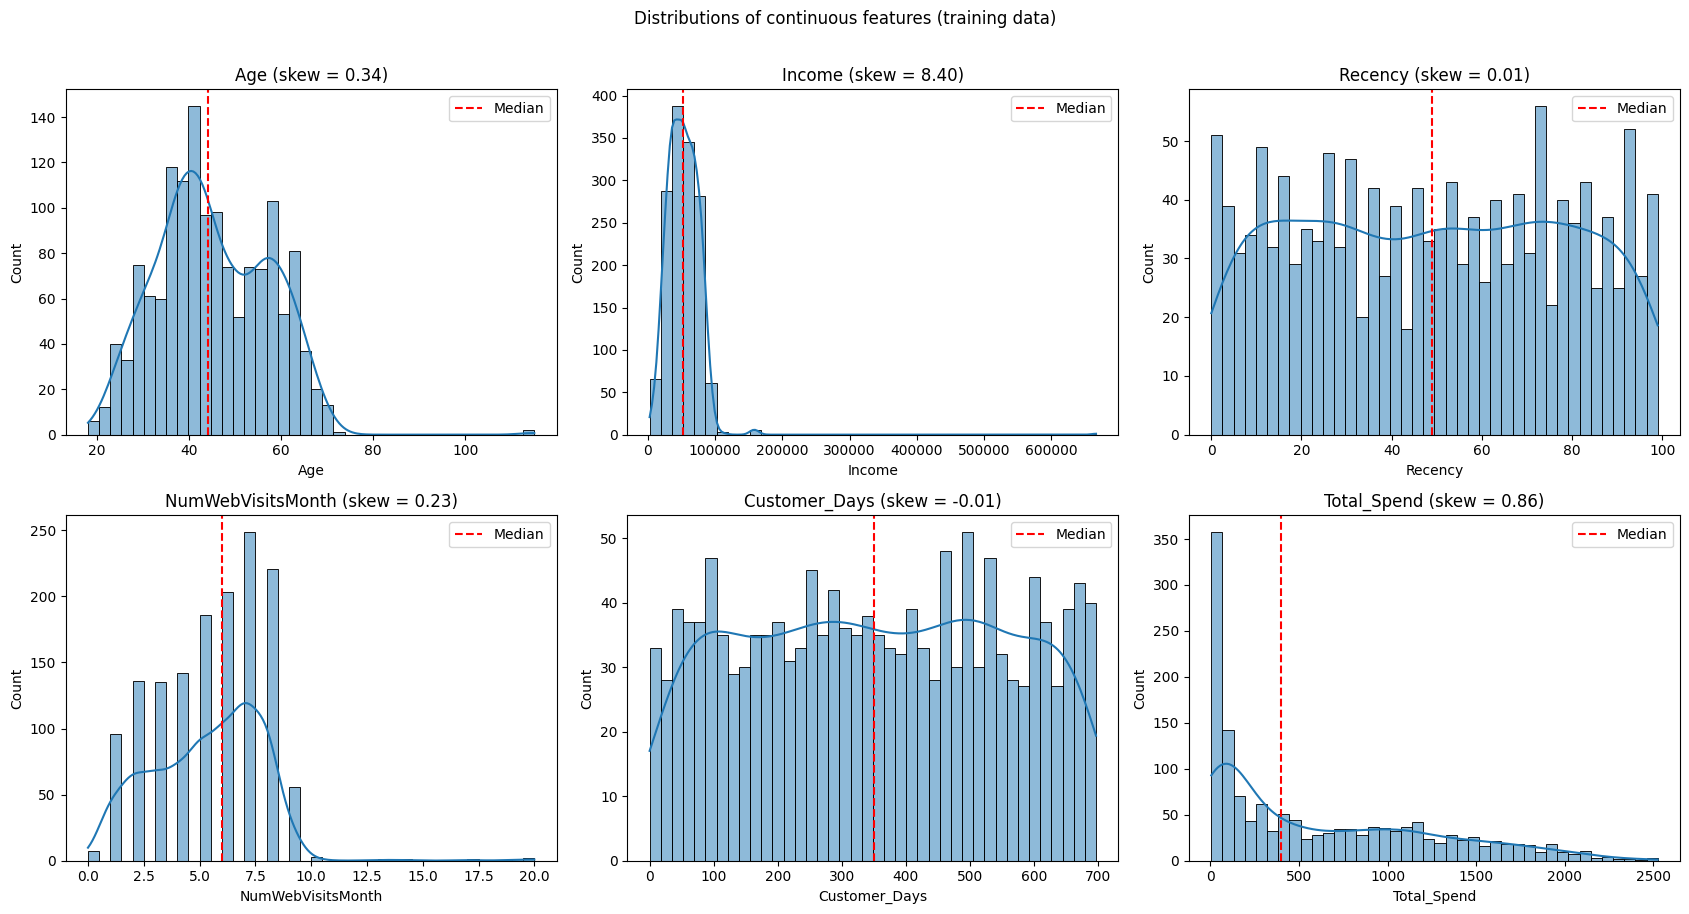

In [17]:
# Histograms
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), cont_cols):
    sns.histplot(train_df[col], bins=40, kde=True, ax=ax)
    ax.axvline(train_df[col].median(), color="red", linestyle="--", label="Median")
    ax.set_title(f"{col} (skew = {train_df[col].skew():.2f})"); ax.legend()
plt.suptitle("Distributions of continuous features (training data)", y=1.01)
plt.tight_layout(); plt.show()

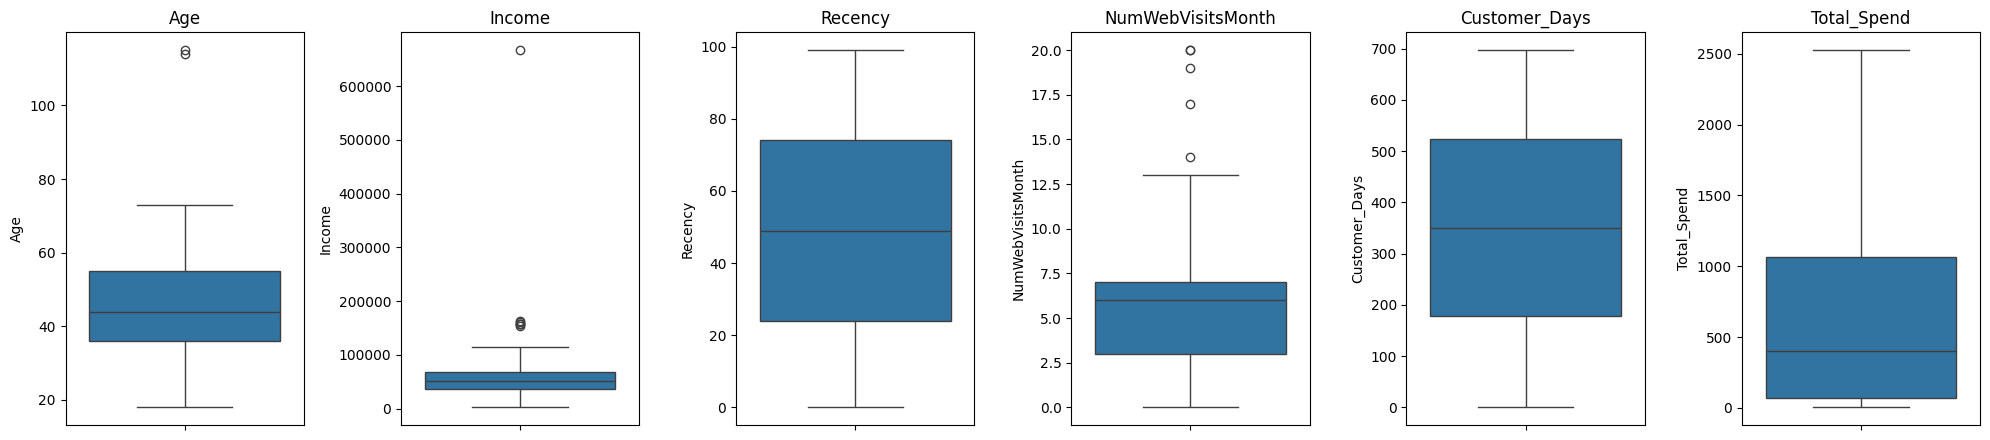

In [18]:
# Boxplots to show outliers
fig, axes = plt.subplots(1, 6, figsize=(20, 4.5))
for ax, col in zip(axes, cont_cols):
    sns.boxplot(y=train_df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()


In [19]:
# Count the extreme values
print("Customers older than 100:", (train_df["Age"] > 100).sum())
print("Birth years of customers older than 100:", sorted(train_df.loc[train_df["Age"] > 100, "Year_Birth"]))
print("Incomes above 200,000:", sorted(train_df.loc[train_df["Income"] > 200000, "Income"]))

Customers older than 100: 2
Birth years of customers older than 100: [1899, 1900]
Incomes above 200,000: [666666.0]


### Interpretation: Distributions of the Continuous Features

Age:
Most customers are between about 25 and 70, with peaks around 40 and 55, so the shape is roughly bell-shaped. The boxplot shows two extreme outliers. The printout confirms they are customers born in 1899 and 1900 (aged 114 and 115), which are almost certainly data-entry errors.

Income:
Income follows a bell shape centred around 50,000, but the single value of 666,666 stretches the whole axis and causes the very high skewness (8.40). A few incomes around 150,000 to 160,000 also appear as outliers in the boxplot, but these are realistic for high earners, so I will keep them. The only income above 200,000 is 666,666.

Recency and Customer_Days:
Both are spread almost evenly across their range (a flat, uniform shape) rather than bell-shaped. Gaussian Naive Bayes assumes each feature follows a normal distribution within each class, so this assumption does not hold well for these two features, which may limit the model's performance.

NumWebVisitsMonth:
Most customers visit the website 1 to 9 times a month, with a few unusual customers at 14 to 20 visits. Because these are whole-number counts, the shape is not perfectly smooth.

Total_Spend:
Total spending is strongly right-skewed: a large group of customers spent less than 100, and a long tail spent up to 2,525. The red median line at 401 is the threshold I will use to create the target. Customers to the right of it will be labelled high spenders.

Gaussian Naive Bayes calculates a mean and standard deviation for each feature in each class, so extreme errors like a 115-year-old customer or an income of 666,666 can distort these values. I will fix them in the next step.

## Step 7: Data Cleaning – Fix Data Errors, Drop Constant Columns and Check Categories

In [20]:
# Values learned from TRAINING data only
age_median = train_df.loc[train_df["Age"] <= 100, "Age"].median()
print("Training median age (excluding errors):", age_median, "| Training median income:", income_median)

for df in [train_df, test_df]:
    # Impossible ages (over 100) -> replace with the training median age
    df.loc[df["Age"] > 100, "Age"] = age_median
    # Placeholder income (over 200,000) -> replace with the training median income
    df.loc[df["Income"] > 200000, "Income"] = income_median
    # Drop constant columns
    df.drop(columns=["Z_CostContact", "Z_Revenue"], inplace=True)

print("\nAfter fixing - Age max (train/test):", train_df["Age"].max(), "/", test_df["Age"].max())
print("After fixing - Income max (train/test):", train_df["Income"].max(), "/", test_df["Income"].max())
print("Income skewness (train) now:", round(train_df["Income"].skew(), 2))


Training median age (excluding errors): 44.0 | Training median income: 51523.5

After fixing - Age max (train/test): 73 / 74
After fixing - Income max (train/test): 162397.0 / 157243.0
Income skewness (train) now: 0.47


In [21]:
# Category counts (training data) - to plan the encoding
print("\nEducation (train):\n", train_df["Education"].value_counts())
print("\nMarital_Status (train):\n", train_df["Marital_Status"].value_counts())


Education (train):
 Education
Graduation    723
PhD           325
Master        235
2n Cycle      116
Basic          41
Name: count, dtype: int64

Marital_Status (train):
 Marital_Status
Married     554
Together    370
Single      312
Divorced    146
Widow        52
Alone         3
Absurd        2
YOLO          1
Name: count, dtype: int64


### Interpretation: Data Cleaning

Data errors:
I replaced the two impossible ages (birth years 1899 and 1900) with the training median age of 44, and the placeholder income of 666,666 with the training median income of 51,523.5. I applied the same rules to the test set, using values learned from the training data only. I replaced the values instead of deleting the customers, because only one value per customer was wrong and the rest of their data was valid. After cleaning, the oldest customer is 73 in training and 74 in testing, and the highest income is about 162,000, which is realistic. Fixing that single income value reduced the skewness of Income from 8.40 to 0.47, so Income is now close to a normal distribution, which suits Gaussian Naive Bayes.

Constant columns:
I dropped Z_CostContact and Z_Revenue because they have the same value for every customer.

Categorical variables:
- Education has five valid levels: Graduation (723), PhD (325), Master (235), 2n Cycle (116) and Basic (41). "2n Cycle" means a second-cycle degree, similar to a master's level in the European system. I will keep all five.
- Marital_Status has five normal categories (Married, Together, Single, Divorced and Widow) and three unusual ones with very few customers: Alone (3), Absurd (2) and YOLO (1). Alone has the same meaning as Single, so I will merge them. Absurd and YOLO are not real marital statuses, so I will replace them with the most common category in the training data, Married.

## Step 8: Feature Encoding and Creating the Target Variable (high_spender)

In [22]:
# 1. Clean Marital_Status categories (rule + most common value from TRAINING data)
marital_mode = train_df["Marital_Status"].mode()[0]
for df in [train_df, test_df]:
    df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single", "Absurd": marital_mode, "YOLO": marital_mode})
print("Marital_Status after cleaning (train):\n", train_df["Marital_Status"].value_counts())

Marital_Status after cleaning (train):
 Marital_Status
Married     557
Together    370
Single      315
Divorced    146
Widow        52
Name: count, dtype: int64


In [23]:
# 2. One-hot encoding (columns learned from TRAINING data)
train_enc = pd.get_dummies(train_df, columns=["Education", "Marital_Status"], drop_first=True, dtype=int)
test_enc = pd.get_dummies(test_df, columns=["Education", "Marital_Status"], drop_first=True, dtype=int)
test_enc = test_enc.reindex(columns=train_enc.columns, fill_value=0)
print("\nNew encoded columns:", [c for c in train_enc.columns if c.startswith(("Education_", "Marital_Status_"))])


New encoded columns: ['Education_Basic', 'Education_Graduation', 'Education_Master', 'Education_PhD', 'Marital_Status_Married', 'Marital_Status_Single', 'Marital_Status_Together', 'Marital_Status_Widow']


In [24]:
# 3. Target: Total_Spend above the TRAINING median = high spender (1)
spend_median = train_df["Total_Spend"].median()
y_train = (train_enc["Total_Spend"] > spend_median).astype(int).rename("high_spender")
y_test = (test_enc["Total_Spend"] > spend_median).astype(int).rename("high_spender")
print(f"\nTotal_Spend median (train): {spend_median}")
print("high_spender proportions (train):", y_train.value_counts(normalize=True).round(3).to_dict())
print("high_spender proportions (test): ", y_test.value_counts(normalize=True).round(3).to_dict())


Total_Spend median (train): 401.0
high_spender proportions (train): {0: 0.502, 1: 0.498}
high_spender proportions (test):  {0: 0.511, 1: 0.489}


In [25]:
# 4. Feature sets
cont_features = ["Age", "Income", "Recency", "NumWebVisitsMonth", "Customer_Days"]
dummy_cols = [c for c in train_enc.columns if c.startswith(("Education_", "Marital_Status_"))]
all_features = cont_features + ["Kidhome", "Teenhome"] + dummy_cols


In [26]:
X_train_cont, X_test_cont = train_enc[cont_features], test_enc[cont_features]
X_train_all, X_test_all = train_enc[all_features], test_enc[all_features]
print("\nContinuous features:", X_train_cont.shape, "| All features:", X_train_all.shape)


Continuous features: (1440, 5) | All features: (1440, 15)


### Interpretation: Feature Encoding and Target Creation

Marital status:
After merging Alone into Single and replacing Absurd and YOLO with the most common category (Married), Marital_Status has five clean categories: Married (557), Together (370), Single (315), Divorced (146) and Widow (52).

Encoding:
I used one-hot encoding with drop_first=True, which created 8 new 0/1 columns: 4 for Education (Basic, Graduation, Master, PhD, each compared with the dropped baseline "2n Cycle") and 4 for Marital_Status (Married, Single, Together, Widow, each compared with the baseline "Divorced"). I aligned the test set to the same columns as the training set.

Target variable:
The median Total_Spend in the training data is 401. Customers who spent more than 401 over two years are labelled as high spenders (1), and the rest as low spenders (0). The classes are almost perfectly balanced: 50.2% low and 49.8% high in training, and 51.1% and 48.9% in testing. Because the classes are balanced, accuracy is a fair metric for this task.

Feature sets:
- Main model: the 5 continuous features (Age, Income, Recency, NumWebVisitsMonth and Customer_Days), as the assignment asks.
- Extra comparison: all 15 features (the continuous features, Kidhome, Teenhome and the 8 encoded columns).
I excluded the six spending columns and Total_Spend, because the target is created from them, and the purchase-count columns, because they measure almost the same thing as spending and would make the task too easy.

## Step 9: Model Implementation – Gaussian Naive Bayes (Continuous Features)

In [27]:
gnb = GaussianNB()
gnb.fit(X_train_cont, y_train)

y_pred = gnb.predict(X_test_cont)
y_prob = gnb.predict_proba(X_test_cont)[:, 1]

In [28]:
# What the model learned: mean of each feature for each class
learned = pd.DataFrame(gnb.theta_, columns=cont_features, index=["Low spender (0)", "High spender (1)"]).round(1)
print("Class priors:", dict(zip(["Low (0)", "High (1)"], gnb.class_prior_.round(3))))
print("\nMean of each feature per class (learned from training data):")
display(learned)

Class priors: {'Low (0)': np.float64(0.502), 'High (1)': np.float64(0.498)}

Mean of each feature per class (learned from training data):


,Age,Income,Recency,NumWebVisitsMonth,Customer_Days
Low spender (0),43.1,37169.2,48.0,6.4,318.5
High spender (1),47.0,67722.0,49.8,4.2,385.8


In [29]:
# Evaluation
print("Train accuracy:", round(accuracy_score(y_train, gnb.predict(X_train_cont)), 3))
print("Test accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))
print("F1-score: ", round(f1_score(y_test, y_pred), 3))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Low spender", "High spender"]))

Train accuracy: 0.862
Test accuracy:  0.867
Precision: 0.877
Recall:    0.848
F1-score:  0.862

Classification report:
              precision    recall  f1-score   support

 Low spender       0.86      0.89      0.87       316
High spender       0.88      0.85      0.86       302

    accuracy                           0.87       618
   macro avg       0.87      0.87      0.87       618
weighted avg       0.87      0.87      0.87       618



### Interpretation: Gaussian Naive Bayes Model (Continuous Features)

What the model learned:
The class priors are 0.502 (low spenders) and 0.498 (high spenders), matching the balanced classes. Gaussian Naive Bayes learned the average value of each feature for each class:
- Income shows the biggest difference: high spenders earn about 67,700 on average, compared with about 37,200 for low spenders. Income is likely the most important feature.
- Low spenders visit the website more often (6.4 visits per month compared with 4.2). They may be browsing or looking for deals without buying much.
- High spenders have been customers longer (about 386 days compared with 319), so loyalty is linked to higher spending.
- High spenders are slightly older (47 compared with 43).
- Recency is almost the same for both groups (48.0 and 49.8 days), so it gives the model very little information.

Performance:
- Test accuracy is 86.7%, and training accuracy is 86.2%. The two are almost identical, so the model is not overfitting. This is typical for Naive Bayes, because it is a simple model with very few parameters.
- For high spenders, precision is 0.877 (when the model predicts a high spender, it is right 87.7% of the time) and recall is 0.848 (it finds 84.8% of the real high spenders). The F1-score is 0.862.
- For low spenders, precision is 0.86 and recall is 0.89.
The model performs well and in a balanced way for both classes, even though only five features were used and some of them (Recency and Customer_Days) are not normally distributed.

## Step 10: Results Interpretation – Confusion Matrix and ROC Curve

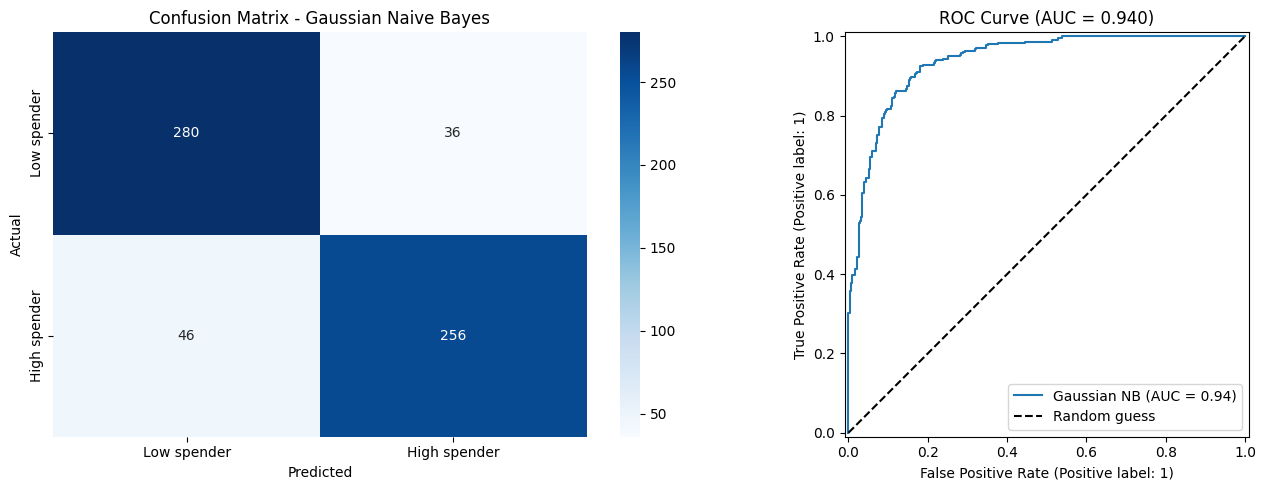

True negatives: 280 | False positives: 36 | False negatives: 46 | True positives: 256
AUC: 0.94


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix (heatmap)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Low spender", "High spender"], yticklabels=["Low spender", "High spender"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion Matrix - Gaussian Naive Bayes")

# ROC curve and AUC
auc = roc_auc_score(y_test, y_prob)
RocCurveDisplay.from_predictions(y_test, y_prob, name="Gaussian NB", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title(f"ROC Curve (AUC = {auc:.3f})"); axes[1].legend()
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives: {tn} | False positives: {fp} | False negatives: {fn} | True positives: {tp}")
print("AUC:", round(auc, 3))

In [31]:
# Look at the mistakes: what do they have in common?
errors = test_enc.assign(actual=y_test, predicted=y_pred, prob_high=y_prob.round(2))
print("\nAverage values - correct vs wrong predictions:")
display(errors.groupby(errors["actual"] == errors["predicted"])[cont_features + ["Total_Spend"]].mean().round(1)
        .rename(index={True: "Correct", False: "Wrong"}))


Average values - correct vs wrong predictions:


,Age,Income,Recency,NumWebVisitsMonth,Customer_Days,Total_Spend
Wrong,48.7,52843.5,45.6,5.5,344.0,446.3
Correct,44.8,51033.6,49.7,5.3,355.1,601.3


### Interpretation: Confusion Matrix and ROC Curve

Confusion matrix:
- 280 low spenders were correctly identified (true negatives).
- 256 high spenders were correctly identified (true positives).
- 36 low spenders were wrongly predicted as high spenders (false positives).
- 46 high spenders were wrongly predicted as low spenders (false negatives).
The model made 82 mistakes out of 618 customers. The errors are fairly balanced, but the model is slightly more likely to miss a high spender than to raise a false alarm.

ROC curve and AUC:
The ROC curve rises steeply towards the top-left corner, far above the random-guess line. The AUC (Area Under the Curve) is 0.940, which means that if I pick one random high spender and one random low spender, the model gives the high spender the higher probability 94% of the time. This shows the model ranks customers very well.

Where the model performed well:
The model separates customers with clearly low or clearly high incomes very well. Income is the strongest signal, because high spenders earn almost twice as much on average as low spenders.

Where the model struggled:
The wrongly classified customers have an average Total_Spend of 446, close to the 401 threshold, compared with 601 for correctly classified customers. Their average income (about 52,800) is almost exactly halfway between the low-spender average (37,200) and the high-spender average (67,700). This is where the two classes overlap, so the model cannot clearly tell them apart. Many of the errors are borderline customers whose spending is just above or below the median. They are hard to classify for any model.

From a marketing point of view, a false negative means missing a valuable customer in a premium campaign, while a false positive means spending money targeting someone who will not spend much. If missing high spenders is more costly, the decision threshold could be lowered to catch more of them.

## Step 11: Model Optimization – With vs Without Feature Scaling

In [32]:
def evaluate_nb(name, model, X_tr, X_te):
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)
    prob = model.predict_proba(X_te)[:, 1]
    cv_acc = cross_validate(model, X_tr, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=random_seed),
                            scoring="accuracy")["test_score"].mean()
    return {"Model": name, "CV accuracy": cv_acc, "Test accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred), "AUC": roc_auc_score(y_test, prob)}

scaled_nb = Pipeline([("scaler", StandardScaler()), ("gnb", GaussianNB())])

compare = pd.DataFrame([
    evaluate_nb("Continuous - no scaling", GaussianNB(), X_train_cont, X_test_cont),
    evaluate_nb("Continuous - StandardScaler", scaled_nb, X_train_cont, X_test_cont),
    evaluate_nb("All features - no scaling", GaussianNB(), X_train_all, X_test_all),
    evaluate_nb("All features - StandardScaler", scaled_nb, X_train_all, X_test_all),
]).round(4)
print(compare.to_string(index=False))

                        Model  CV accuracy  Test accuracy  Precision  Recall     F1    AUC
      Continuous - no scaling       0.8625         0.8673     0.8767  0.8477 0.8620 0.9401
  Continuous - StandardScaler       0.8604         0.8592     0.8694  0.8377 0.8533 0.9376
    All features - no scaling       0.8715         0.8625     0.8653  0.8510 0.8581 0.9425
All features - StandardScaler       0.7917         0.8333     0.8043  0.8709 0.8362 0.9171


In [33]:
# Are the predictions literally identical with and without scaling?
p_raw = GaussianNB().fit(X_train_cont, y_train).predict(X_test_cont)
p_scaled = scaled_nb.fit(X_train_cont, y_train).predict(X_test_cont)
print("\nPredictions that differ between scaled and unscaled (continuous):", (p_raw != p_scaled).sum(), "of", len(p_raw))



Predictions that differ between scaled and unscaled (continuous): 5 of 618


### Interpretation: Feature Scaling Comparison

Continuous features only:
Scaling made almost no difference. Test accuracy went from 86.7% without scaling to 85.9% with scaling, CV accuracy from 86.3% to 86.0%, and AUC from 0.940 to 0.938. Only 5 of the 618 test predictions changed. This is expected for Gaussian Naive Bayes: it models each feature separately, using that feature's own mean and variance in each class, and it does not use distances like k-NN or SVM. Scaling stretches the bell curves of both classes in the same way, so the comparison between classes barely changes.

The small difference comes from a setting called var_smoothing. To avoid dividing by zero, Gaussian Naive Bayes adds a small number to every feature's variance, calculated as a tiny fraction of the largest variance of any feature. Without scaling, the largest variance is Income's, so the added number is relatively large. With scaling, all variances are about 1, so the added number is tiny.

All features (continuous plus encoded categories):
Without scaling, using all 15 features gave a CV accuracy of 87.2% and a test accuracy of 86.3%, similar to the continuous-only model. With scaling, performance dropped clearly: CV accuracy fell to 79.2% and test accuracy to 83.3%. The encoded categories are 0/1 columns, which are not normally distributed. Without scaling, the smoothing added because of Income's large variance flattens these small-variance columns, so the model mostly ignores them. After scaling, they get full weight, and because they break the Gaussian (bell curve) assumption, they mislead the model.

Conclusion:
Feature scaling does not improve Gaussian Naive Bayes. The best and simplest model is the continuous-only model without scaling (test accuracy 86.7%, F1 0.862, AUC 0.940). Adding the encoded categorical features did not improve the results. For binary features, a Bernoulli Naive Bayes model would be more suitable than Gaussian Naive Bayes.

## Step 12: Report – Gaussian Naive Bayes on Customer Spending

### Steps followed
**Data:** I used the Customer Personality Analysis dataset from Kaggle (2,240 customers, 29 columns) instead of the Insurance Charges dataset. The goal was the same: classify individuals by whether a money amount (total spending over two years instead of medical charges) is above or below the median.

**Preprocessing:**
1. Removed 182 duplicate customers that had identical values in every column except ID, leaving 2,058 customers.
2. Split the data into training (70%, 1,440 customers) and testing (30%, 618 customers) sets before any further analysis.
3. Filled 24 missing Income values with the training median (51,523.5).
4. Created Age, Customer_Days (how long they had been a customer) and Total_Spend (the sum of six product categories).
5. Fixed data errors: two impossible ages (birth years 1899 and 1900) and a placeholder income of 666,666, both replaced with training medians. This reduced Income's skewness from 8.40 to 0.47.
6. Dropped two constant columns (Z_CostContact and Z_Revenue), and cleaned the rare Marital_Status values (Alone, Absurd and YOLO).
7. One-hot encoded Education and Marital_Status.
8. Created the target, high_spender = 1 if Total_Spend is above the training median of 401, otherwise 0. The classes were balanced (about 50/50).

**Model:** Gaussian Naive Bayes, trained on five continuous features (Age, Income, Recency, NumWebVisitsMonth and Customer_Days), as the assignment asks. I excluded the spending and purchase-count columns to avoid data leakage.

### Performance

| Model | CV accuracy | Test accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|---|
| **Continuous - no scaling** | 0.863 | **0.867** | **0.877** | 0.848 | **0.862** | 0.940 |
| Continuous - StandardScaler | 0.860 | 0.859 | 0.869 | 0.838 | 0.853 | 0.938 |
| All features - no scaling | 0.872 | 0.863 | 0.865 | 0.851 | 0.858 | 0.943 |
| All features - StandardScaler | 0.792 | 0.833 | 0.804 | 0.871 | 0.836 | 0.917 |

Confusion matrix (best model): 280 true negatives, 256 true positives, 36 false positives and 46 false negatives.

### Discussion
**Where the model performed well:** Gaussian Naive Bayes reached 86.7% test accuracy and an AUC of 0.940 using only five simple features, with no tuning. Training and test accuracy were almost identical (86.2% and 86.7%), so the model did not overfit. Income was the strongest signal: high spenders earn almost twice as much as low spenders on average (about 67,700 compared with 37,200). Other useful patterns were that high spenders have been customers longer, and low spenders visit the website more often without buying much.

**Where it struggled:** The 82 errors (36 false positives and 46 false negatives) were mostly borderline customers. Their average spending (446) was close to the 401 threshold, and their average income (about 52,800) was halfway between the two class averages, where the classes overlap. The model also relies on assumptions that are not fully met: Recency and Customer_Days are evenly spread rather than bell-shaped, and the features are not completely independent.

**Effect of feature scaling:** Scaling did not improve the model. With continuous features only, results were almost unchanged (only 5 of 618 predictions differed), because Gaussian Naive Bayes models each feature separately with its own mean and variance and does not use distances. The small changes came from the variance smoothing setting. When the encoded 0/1 features were included, scaling made performance worse (CV accuracy dropped from 87.2% to 79.2%), because the scaled binary columns break the bell-curve assumption.

**Improvements made:** Removing duplicate customers, fixing data errors (which made Income almost normally distributed) and avoiding leakage features all made the model more reliable. Possible further improvements: try Bernoulli Naive Bayes for the binary features, lower the threshold if missing high spenders is more costly, and compare with other models such as logistic regression or Random Forest.

### Business takeaway
The model can identify likely high spenders from basic customer information (income, age, loyalty and website visits) with about 87% accuracy. A marketing team could use it to target premium offers at likely high spenders, while paying attention to the borderline middle-income group, where predictions are least certain.